In [1]:


import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Set visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:


# Load the built-in Iris dataset
iris = load_iris()

# Convert dataset into a Pandas DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the target column
df['species'] = iris.target

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
# Step 4: Basic Exploratory Data Analysis (EDA)

print("Dataset Shape:", df.shape)

print("\nColumn Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDescriptive Statistics:")
display(df.describe())

Dataset Shape: (150, 5)

Column Data Types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                int64
dtype: object

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Descriptive Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


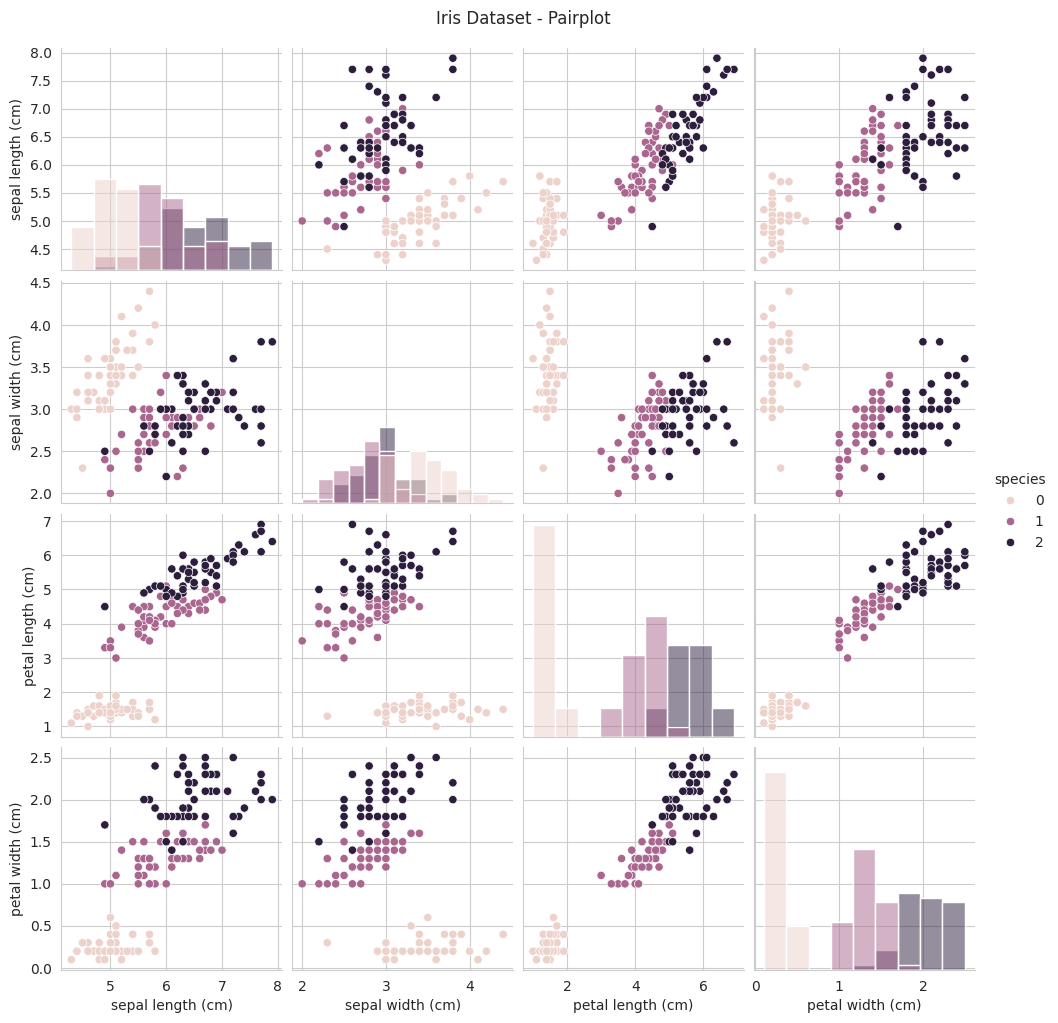

In [4]:
# Step 5: Pairplot Visualization

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Iris Dataset - Pairplot", y=1.02)
plt.show()

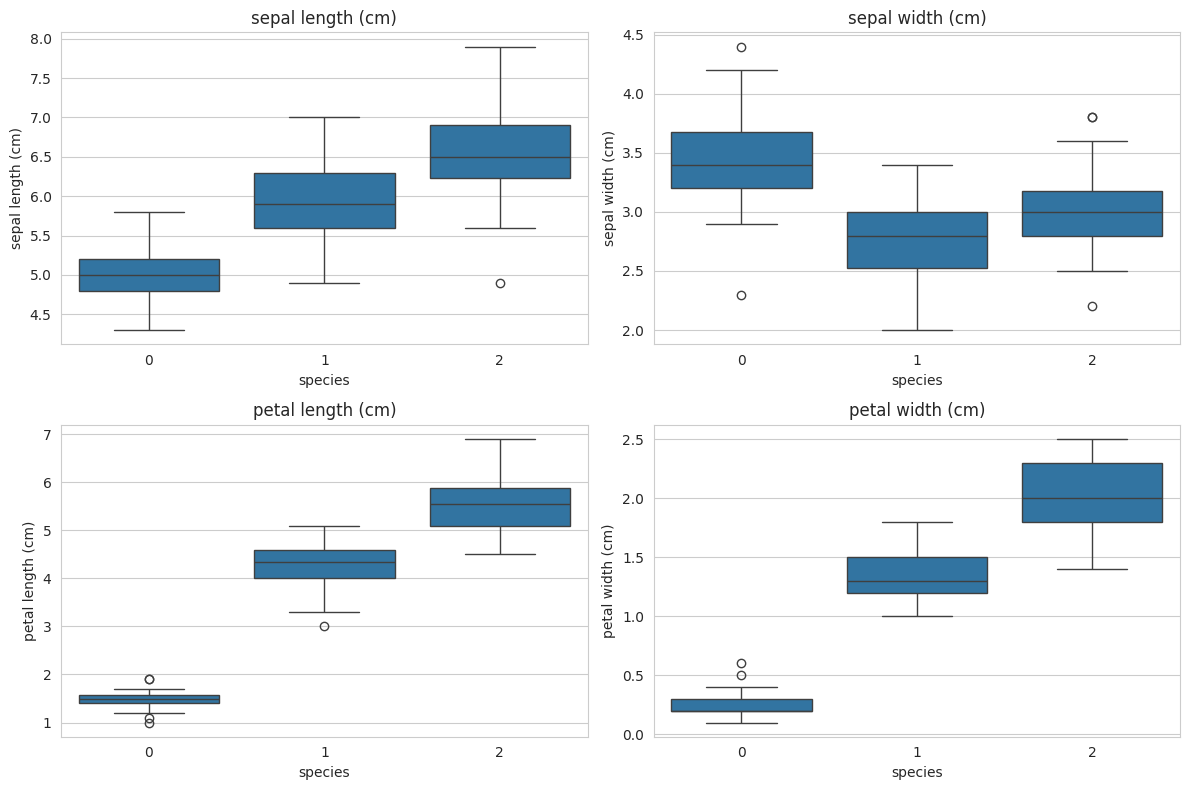

In [5]:
# Step 6: Boxplots for All Features

plt.figure(figsize=(12, 8))

for i, column in enumerate(iris.feature_names, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x="species", y=column, data=df)
    plt.title(column)

plt.tight_layout()
plt.show()

In [6]:
# Step 7: Feature Selection

features = iris.feature_names

for feature in features:
    print("\nFeature:", feature)
    print(df.groupby("species")[feature].mean())


Feature: sepal length (cm)
species
0    5.006
1    5.936
2    6.588
Name: sepal length (cm), dtype: float64

Feature: sepal width (cm)
species
0    3.428
1    2.770
2    2.974
Name: sepal width (cm), dtype: float64

Feature: petal length (cm)
species
0    1.462
1    4.260
2    5.552
Name: petal length (cm), dtype: float64

Feature: petal width (cm)
species
0    0.246
1    1.326
2    2.026
Name: petal width (cm), dtype: float64


In [7]:
# Step 8: Train-Test Split

X = df.drop("species", axis=1)
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (120, 4)
Testing data shape: (30, 4)


In [8]:
# Step 9: Logistic Regression Model

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create the model
model_lr = LogisticRegression(max_iter=200)

# Train the model
model_lr.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [9]:
# Step 10: Evaluate Logistic Regression

y_pred_lr = model_lr.predict(X_test_scaled)

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=iris.target_names))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 93.33333333333333 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [10]:
# Step 11: KNN Model

model_knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
model_knn.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [11]:
# Step 12: Evaluate KNN Model

y_pred_knn = model_knn.predict(X_test_scaled)

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", accuracy_knn * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=iris.target_names
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

KNN Accuracy: 93.33333333333333 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


In [12]:
# Step 13: Compare Both Models

print("Logistic Regression Accuracy:", accuracy_lr * 100, "%")
print("KNN Accuracy:", accuracy_knn * 100, "%")

if accuracy_lr > accuracy_knn:
    print("\nBest Model: Logistic Regression")
elif accuracy_knn > accuracy_lr:
    print("\nBest Model: KNN")
else:
    print("\nBoth models have the same accuracy!")

Logistic Regression Accuracy: 93.33333333333333 %
KNN Accuracy: 93.33333333333333 %

Both models have the same accuracy!


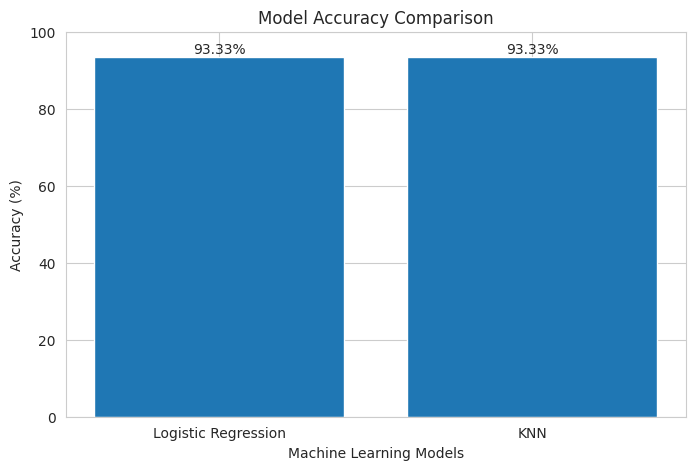

In [13]:
# Step 14: Model Accuracy Comparison Graph

models = ["Logistic Regression", "KNN"]
accuracies = [accuracy_lr * 100, accuracy_knn * 100]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

Conclusion – Iris Flower Classification

In this project, I developed machine learning models to classify Iris flowers into three species: Setosa, Versicolor, and Virginica.

Work Completed

- Loaded and explored the Iris dataset.
- Performed data analysis and visualisation.
- Selected important features.
- Split the dataset into training and testing sets.
- Trained Logistic Regression and K-Nearest Neighbors (KNN) models.
- Evaluated both models using accuracy, confusion matrices, precision, recall, and F1-score.

Results

- Logistic Regression Accuracy: 93.33%
- KNN Accuracy: 93.33%

Both models achieved the same accuracy on the test dataset.

Final Conclusion

This project helped me understand data preprocessing, data visualisation, classification algorithms, and model evaluation using Python and Scikit-learn.